# Local Search Heuristics for the 0/1 Knapsack Problem

---

### Learning Objectives

By the end of this lab session, you will be able to:

1. **Understand** the 0/1 Knapsack Problem and its complexity
2. **Implement** various local search-based metaheuristics
3. **Compare** heuristic solutions with exact optimal solutions (Gurobi)
4. **Analyze** the trade-offs between solution quality and computational time
5. **Visualize** convergence behavior of different algorithms

---

### Problem Definition

The **0/1 Knapsack Problem** is a classic NP-hard combinatorial optimization problem.

**Given:**
- A set of $n$ items: $N = \{1, 2, \dots, n\}$
- Each item $i$ has:
  - A value: $v_i > 0$
  - A weight: $w_i > 0$
- A knapsack with capacity: $W > 0$

**Goal:** Select a subset of items to maximize total value without exceeding the weight capacity.

**Mathematical Formulation:**

$$\max Z = \sum_{i=1}^{n} v_i x_i$$

$$\text{subject to: } \sum_{i=1}^{n} w_i x_i \leq W$$

$$x_i \in \{0, 1\}, \quad \forall i \in N$$

where $x_i = 1$ if item $i$ is selected, and $x_i = 0$ otherwise.

---

### Algorithms Implemented

1. **Gurobi Solver** - Provides optimal solutions for comparison
2. **Local Search (LS)** - Best Improvement and First Improvement strategies
3. **Iterated Local Search (ILS)** - Escapes local optima through perturbation
4. **Variable Neighborhood Search (VNS)** - Systematically changes neighborhoods
5. **Guided Local Search (GLS)** - Uses penalties to guide the search

---

##  Part 1:  Experimental Setup


### 1.1 Libraries Importation

In this section, we import all necessary libraries and modules required for the implementation of the heuristics and data handling. Additional libraries may be imported as needed for specific functionalities. We also define the output directories to organize the results, plots, and statistics generated during the experiments.


In [1]:
import numpy as np # For numerical operations
import matplotlib.pyplot as plt # For plotting
import time # For timing operations
import os # For operating system interactions
from gurobipy import GRB, Model, quicksum # For optimization modeling
import openpyxl as pxl # For Excel file manipulation
from openpyxl.styles import Font, PatternFill, Alignment # For styling Excel cells
import pandas as pd # For data manipulation
from collections import defaultdict # For default dictionary
import gc  # For garbage collection to manage memory
import warnings  # For warning suppression
warnings.filterwarnings('ignore')

# Optional: Try to import tqdm for progress bars
try:
    from tqdm import tqdm
    TQDM_AVAILABLE = True
    print("✓ tqdm available - progress bars enabled")
except ImportError:
    TQDM_AVAILABLE = False
    print("ℹ tqdm not available - progress bars disabled (install with: pip install tqdm)")

# Create necessary directories
os.makedirs('plots', exist_ok=True) # For convergence plots
os.makedirs('statistics', exist_ok=True) # For detailed Excel statistics
os.makedirs('results', exist_ok=True) # For summary reports

print("✓ All libraries imported successfully")
print("✓ Output directories created: plots/, statistics/, results/")

✓ tqdm available - progress bars enabled
✓ All libraries imported successfully
✓ Output directories created: plots/, statistics/, results/


### 1.2 Testing Configuration

**Purpose**: Set the number of instances to test.

**Options**:
- `max_instances = 50`: Quick test (recommended for lab - takes ~1-2 minutes)
- `max_instances = 1000`: Full test (comprehensive - takes hours)

**Note**: You can change this value at any time and re-run the notebook.

In [2]:
# Configuration: Number of instances to test
max_instances = 50  # Change to 1000 for full testing

print(f"Configuration: Testing up to {max_instances} instances")
print(f"Mode: {'FULL TEST (all instances)' if max_instances >= 1000 else 'DEFAULT TEST (sample instances)'}")

Configuration: Testing up to 50 instances
Mode: DEFAULT TEST (sample instances)


### 1.3 Algorithm Configuration Class

**Purpose**: Centralize and standardize algorithm parameters for fair comparison.

**Key Principles**:
1. **Time Budget Fairness**: All algorithms get equal maximum runtime
2. **Instance-Size Scaling**: Parameters scale with problem size
3. **Computational Budget**: Iteration limits based on neighborhood size
4. **Consistency**: Same neighborhood structures across algorithms

**Parameters**:
- `time_budget`: Maximum time per algorithm (default: 60 seconds)
- `max_evaluations`: Scales with instance size (n × multiplier)
- `perturbation_rate`: Percentage of solution to perturb (5-10%)
- `vns_k_max`: Number of neighborhood structures (4)
- `gls_lambda`: Penalty weight (auto-tuned based on value range)

In [3]:
class AlgorithmConfig:
    """
    Configuration class for algorithm parameters.
    Ensures fair comparison by scaling parameters with instance size.
    """
    
    def __init__(self, n_items, time_budget=60):
        """
        Initialize configuration based on instance size.
        
        Args:
            n_items: Number of items in the instance
            time_budget: Maximum time budget per algorithm (seconds)
        """
        self.n_items = n_items
        self.time_budget = time_budget
        
        # Scale iterations with problem size
        # For smaller instances: more thorough search
        # For larger instances: limited by computational budget
        if n_items <= 100:
            self.ls_max_iter = 10000
            self.ils_iterations = 100
            self.vns_iterations = 100
            self.gls_iterations = 100
        elif n_items <= 1000:
            self.ls_max_iter = 5000
            self.ils_iterations = 50
            self.vns_iterations = 50
            self.gls_iterations = 50
        elif n_items <= 10000:
            self.ls_max_iter = 1000
            self.ils_iterations = 20
            self.vns_iterations = 20
            self.gls_iterations = 20
        else:  # Very large instances
            self.ls_max_iter = 500
            self.ils_iterations = 10
            self.vns_iterations = 10
            self.gls_iterations = 10
        
        # Local search iterations within ILS/VNS/GLS
        self.ls_inner_max_iter = min(500, self.ls_max_iter // 2)
        
        # Perturbation strength: 5-10% of items
        self.perturbation_strength = max(3, int(n_items * 0.05))
        
        # VNS neighborhood structures
        self.vns_k_max = 4
        
        # GLS lambda parameter (auto-tuned)
        # Will be set based on instance values
        self.gls_lambda = 0.1
        
    def update_gls_lambda(self, avg_value):
        """Update GLS lambda based on average item value"""
        if avg_value > 0:
            self.gls_lambda = avg_value / (self.n_items * 10)
        else:
            self.gls_lambda = 0.1
    
    def __str__(self):
        """String representation for debugging"""
        return f"""AlgorithmConfig(n_items={self.n_items}):
  - LS max_iter: {self.ls_max_iter}
  - ILS iterations: {self.ils_iterations}
  - VNS iterations: {self.vns_iterations}
  - GLS iterations: {self.gls_iterations}
  - LS inner max_iter: {self.ls_inner_max_iter}
  - Perturbation strength: {self.perturbation_strength}
  - Time budget: {self.time_budget}s"""
print("✓ AlgorithmConfig class defined\n")

# # Test the configuration class
# test_config_small = AlgorithmConfig(n_items=100, time_budget=60)
# test_config_medium = AlgorithmConfig(n_items=5000, time_budget=60)
# test_config_large = AlgorithmConfig(n_items=100000, time_budget=60)

# print("✓ AlgorithmConfig class defined\n")
# print("Small instance (100 items):")
# print(test_config_small)
# print("\nMedium instance (5000 items):")
# print(test_config_medium)
# print("\nLarge instance (100000 items):")
# print(test_config_large)

✓ AlgorithmConfig class defined



### 1.4 Instance Management Functions

**Purpose**: Define functions to handle knapsack problem instances efficiently.

**Key Features**:
- **Memory Efficient**: Load instances one at a time (not all at once)
- **Lazy Loading**: Instance data loaded only when needed
- **Scalable**: Can handle hundreds of instances without memory issues

**Functions**:
1. `get_instance_list()`: Lists available instance files without loading data
2. `load_single_instance()`: Loads a single instance from Excel file
3. `extract_instance_info()`: Extracts metadata (size) from filename

In [4]:
def get_instance_list(directory='kp_instances', max_count=None):
    """
    Get list of instance files without loading them.
    
    Args:
        directory: Directory containing instance files
        max_count: Maximum number of instances to list (None = all)
    
    Returns:
        List of (filename, filepath) tuples
    """
    instances = []
    for filename in sorted(os.listdir(directory)):
        if filename.endswith('.xlsx'):
            filepath = os.path.join(directory, filename)
            instances.append((filename, filepath))
            if max_count and len(instances) >= max_count:
                break
    return instances

def load_single_instance(filepath):
    """
    Load a single instance from file.
    Memory efficient - loads only when needed.
    
    Args:
        filepath: Path to the instance file
    
    Returns:
        Dictionary with 'weights', 'values', 'capacity', 'n_items'
    """
    wb = pxl.load_workbook(filepath, read_only=True, data_only=True)
    sheet = wb.active
    
    weights = []
    values = []
    capacity = None
    
    for row in sheet.iter_rows(min_row=2, values_only=True):
        if row[0] is not None and row[1] is not None:
            weights.append(int(row[0]))
            values.append(int(row[1]))
        if row[2] is not None and capacity is None:
            capacity = int(row[2])
    
    wb.close()
    
    return {
        'weights': np.array(weights),
        'values': np.array(values),
        'capacity': capacity,
        'n_items': len(weights)
    }

def extract_instance_info(filename):
    """
    Extract size information from filename.
    Example: 'kp_100_items_1.xlsx' -> size=100
    """
    try:
        parts = filename.replace('.xlsx', '').split('_')
        for i, part in enumerate(parts):
            if 'items' in part.lower() or part.isdigit():
                if part.isdigit():
                    return int(part)
                elif i > 0 and parts[i-1].isdigit():
                    return int(parts[i-1])
        return 0
    except:
        return 0

print("✓ Instance management functions defined")

# # Test the instance loading functions
# instances = get_instance_list(max_count=10)
# for fname, fpath in instances:
#     data = load_single_instance(fpath)
#     size = extract_instance_info(fname)
#     print(f"Loaded instance '{fname}' with size {size}:")
#     print(f"  Number of items: {data['n_items']}")
#     print(f"  Capacity: {data['capacity']}")
#     print(f"  Weights: {data['weights'][:5]}...")  # Show first 5 weights
#     print(f"  Values: {data['values'][:5]}...")    # Show first 5 values
# print("✓ Instance loading functions tested successfully")
# # Output Directory Structure:
# # kp_instances/    → Input instance file
# # plots/           → Convergence plots
# # statistics/      → Detailed Excel statistics
# # results/        → Summary reports

✓ Instance management functions defined


---

## Part 2: Solution Encoding and Evaluation

**Understanding how solutions are encoded and evaluated is fundamental to implementing local search algorithms.**

### 2.1 Solution Encoding and Evaluation Functions

**Solution Encoding**: Each solution is represented as a **binary vector** of length $n$:
- `solution[i] = 1` → item $i$ is included in the knapsack
- `solution[i] = 0` → item $i$ is NOT included

**Example**: For 5 items, `[1, 0, 1, 0, 1]` means items 1, 3, and 5 are selected.
If we move from solution `[1, 0, 1, 0, 1]` to its neighbor `[0, 1, 1, 0, 1]`, evaluating the new neighbor solution involves recalculating the total value and weight based on the updated selection of items.

**Functions Implemented**:
1. `evaluate_solution()`: Calculates total value (returns -1 if infeasible), i.e, calculates the objective function value.
2. `is_feasible()`: Checks if total weight ≤ capacity
3. `get_solution_stats()`: Returns detailed statistics (value, weight, utilization)

**Why This Matters**: Efficient evaluation is crucial as it's called thousands of times during search.

In [5]:
def evaluate_solution(solution, values, weights, capacity):
    """
    Evaluate the total value of a solution.
    
    Args:
        solution: Binary vector indicating selected items
        values: Array of item values
        weights: Array of item weights
        capacity: Knapsack capacity
    
    Returns:
        Total value (-1 if infeasible)
    """
    total_weight = np.sum(solution * weights)
    if is_feasible(solution, weights, capacity):
        return np.sum(solution * values)
    return -1  # Infeasible solution

def is_feasible(solution, weights, capacity):
    """
    Check if a solution is feasible.
    
    Args:
        solution: Binary vector
        weights: Array of item weights
        capacity: Knapsack capacity
    
    Returns:
        True if feasible, False otherwise
    """
    return np.sum(solution * weights) <= capacity

def get_solution_stats(solution, values, weights, capacity):
    """
    Get detailed statistics about a solution.
    
    Returns:
        Dictionary with value, weight, num_items, feasible
    """
    total_weight = int(np.sum(solution * weights))
    total_value = int(np.sum(solution * values))
    num_items = int(np.sum(solution))
    feasible = "True" if (total_weight <= capacity) else "False"
    
    return {
        'value': total_value if feasible == "True" else -1,
        'weight': total_weight,
        'num_items': int(num_items),
        'feasible': feasible,
        'utilization': (total_weight / capacity * 100) if capacity > 0 else 0
    }

print("✓ Solution evaluation functions defined")

# Test the solution evaluation functions
test_solution = np.array([1, 0, 1, 1, 0])  # Example solution
test_values = np.array([10, 20, 30, 40, 50])
test_weights = np.array([5, 10, 15, 20, 25])
test_capacity = 40
# Evaluate test solution
test_value = evaluate_solution(test_solution, test_values, test_weights, test_capacity)
test_stats = get_solution_stats(test_solution, test_values, test_weights, test_capacity)
print(f"Test solution value: {test_value}")
print(f"Test solution stats: {test_stats}")

print("✓ Solution evaluation functions tested successfully")

✓ Solution evaluation functions defined
Test solution value: 80
Test solution stats: {'value': 80, 'weight': 40, 'num_items': 3, 'feasible': 'True', 'utilization': 100.0}
✓ Solution evaluation functions tested successfully


---

## Part 3: Constructive Heuristics

**Before applying local search, we need a good starting solution.**

We can use many constructive heuristics to generate an initial feasible solution. A common approaches are:
- **Greedy algorithm** based on the value-to-weight ratio of items.
- **Randomized approaches** to diversify starting points.

### 3.1 Greedy Constructive Heuristic

**Purpose**: Generate a good initial feasible solution quickly.

**Algorithm**: Greedy by value-to-weight ratio
1. Calculate efficiency ratio for each item: $r_i = v_i / w_i$
2. Sort items by ratio (decreasing order)
3. Add items one by one until capacity is reached

**Strategies Available**:
- `'ratio'`: Sort by $v_i / w_i$ (default, usually best)
- `'value'`: Sort by value $v_i$ (decreasing order)
- `'weight'`: Sort by weight $w_i$ (increasing order)

**Complexity**: $O(n \log n)$ due to sorting 

**Why Greedy?** Provides a good starting point for local search (typically 70-90% of optimal).

In [6]:
def greedy_constructive_heuristic(values, weights, capacity, strategy='ratio'):
    """
    Generate initial solution using greedy heuristic.
    
    Args:
        values: Array of item values
        weights: Array of item weights
        capacity: Knapsack capacity
        strategy: 'ratio' (value/weight), 'value', or 'weight'
    
    Returns:
        Binary solution vector
    """
    n = len(values)
    solution = np.zeros(n, dtype=int)
    
    if strategy == 'ratio':
        # Sort by value-to-weight ratio (descending)
        ratio = values / weights
        sorted_indices = np.argsort(-ratio)
    elif strategy == 'value':
        # Sort by value (descending)
        sorted_indices = np.argsort(-values)
    else:  # 'weight'
        # Sort by weight (ascending)
        sorted_indices = np.argsort(weights)
    
    total_weight = 0
    for idx in sorted_indices:
        if total_weight + weights[idx] <= capacity:
            solution[idx] = 1
            total_weight += weights[idx]
    
    return solution

print("✓ Initial solution generator defined")

# Test the greedy constructive heuristic
initial_solution = greedy_constructive_heuristic(
    test_values, test_weights, test_capacity, strategy='ratio'
)
initial_stats = get_solution_stats(initial_solution, test_values, test_weights, test_capacity)
print(f"Initial solution stats (greedy ratio): {initial_stats}")

print("✓ Greedy constructive heuristic tested successfully")   

✓ Initial solution generator defined
Initial solution stats (greedy ratio): {'value': 60, 'weight': 30, 'num_items': 3, 'feasible': 'True', 'utilization': 75.0}
✓ Greedy constructive heuristic tested successfully


### 3.2 Randomized Constructive Heuristic

**Purpose**: Generate diverse initial solutions to explore different areas of the solution space.

**Algorithm**: Randomized selection with feasibility check
1. Randomly shuffle the list of items
2. Iteratively add items to the knapsack if they fit until capacity is reached.
3. Return the constructed solution

**Complexity**: $O(n)$ on average, depending on the number of items added before reaching capacity.

**Why Randomized?** Helps in escaping local optima by providing varied starting points for local search.


In [7]:
def random_constructive_heuristic(values, weights, capacity):
    """
    Generate initial solution using randomized heuristic.
    
    Args:
        values: Array of item values
        weights: Array of item weights
        capacity: Knapsack capacity
    
    Returns:
        Binary solution vector
    """
    n = len(values)
    solution = np.zeros(n, dtype=int)
    
    indices = np.arange(n)
    np.random.shuffle(indices)
    
    total_weight = 0
    for idx in indices:
        if total_weight + weights[idx] <= capacity:
            solution[idx] = 1
            total_weight += weights[idx]
    
    return solution

print("✓ Randomized initial solution generator defined")

# Test the randomized constructive heuristic
random_solution = random_constructive_heuristic(
    test_values, test_weights, test_capacity
)
random_stats = get_solution_stats(random_solution, test_values, test_weights, test_capacity)
print(f"Random solution stats: {random_stats}")

print("✓ Randomized constructive heuristic tested successfully")

✓ Randomized initial solution generator defined
Random solution stats: {'value': 80, 'weight': 40, 'num_items': 2, 'feasible': 'True', 'utilization': 100.0}
✓ Randomized constructive heuristic tested successfully


---

## Part 4: Neighborhood Structure(s)

Local search algorithms explore the solution space by moving from one solution to neighboring solutions.

**The choice of neighborhood structure significantly impacts the performance of local search algorithms.**

**Definition**: A **neighborhood** $N(s)$ of a solution $s$ is the set of solutions that can be reached by applying **a small modification**.

**Three Neighborhood Structures for Knapsack Problem**:

**N1 (1-flip): Flip one bit (add OR remove one item)**
   - **Example**: Current solution `s=[1, 0, 1, 1, 0]` → neighbors:
     - `s1=[0, 0, 1, 1, 0]` (flip position 0)
     - `s2=[1, 1, 1, 1, 0]` (flip position 1)
     - `s3=[1, 0, 0, 1, 0]` (flip position 2)
     - `s4=[1, 0, 1, 0, 0]` (flip position 3)
     - `s5=[1, 0, 1, 1, 1]` (flip position 4)
   - **Size**: $|N_1(s)| = n$

**N2 (2-flip-adjacent): Flip two consecutive bits simultaneously**
   - **Example**: `[1, 0, 1, 1, 0]` → 
     - `[0, 1, 1, 1, 0]` (flip positions 0,1)
     - `[1, 1, 0, 1, 0]` (flip positions 1,2)
     - `[1, 0, 0, 0, 0]` (flip positions 2,3)
     - `[1, 0, 1, 0, 1]` (flip positions 3,4)
     - `[0, 0, 1, 1, 1]` (flip positions 4,0 - circular)
   - **Size**: $|N_2(s)| = n$
  
**N3 (swap): Remove one item AND add another (flip one 1→0 and one 0→1)**
   - **Example**: `[1, 0, 1, 1, 0]` → 
     - `[0, 1, 1, 1, 0]` (remove position 0, add position 1)
     - `[0, 0, 1, 1, 1]` (remove position 0, add position 4)
     - `[1, 1, 0, 1, 0]` (remove position 2, add position 1)
     - `[1, 0, 0, 1, 1]` (remove position 2, add position 4)
     - `[1, 1, 1, 0, 0]` (remove position 3, add position 1)
     - `[1, 0, 1, 0, 1]` (remove position 3, add position 4)
   - **Size**: $|N_3(s)| = k \times (n-k)$ where $k$ = number of 1s in the solution
   - For the example: $k = 3$ (three 1s), $n = 5$, so $|N_3(s)| = 3 \times 2 = 6$ neighbors

**N4 (2-flip): Flip any two bits simultaneously**
   - **Example**: `[1, 0, 1, 1, 0]` → 
     - `[0, 1, 1, 1, 0]` (flip positions 0,1)
     - `[0, 0, 0, 1, 0]` (flip positions 0,2)
     - `[0, 0, 1, 0, 0]` (flip positions 0,3)
     - `[0, 0, 1, 1, 1]` (flip positions 0,4)
     - `[1, 1, 0, 1, 0]` (flip positions 1,2)
     - `[1, 1, 1, 0, 0]` (flip positions 1,3)
     - `[1, 1, 1, 1, 1]` (flip positions 1,4)
     - `[1, 0, 0, 0, 0]` (flip positions 2,3)
     - `[1, 0, 0, 1, 1]` (flip positions 2,4)
     - `[1, 0, 1, 0, 1]` (flip positions 3,4)
   - **Size**: $|N_{4}(s)| = \frac{n(n-1)}{2}$
   - For the example: $n = 5$, so $|N_{4}(s)| = \frac{5 \times 4}{2} = 10$ neighbors

**Feasibility Check**: Only feasible neighbors (weight ≤ capacity) are generated.

**Complexity**: 
- N1: $O(n)$
- N2: $O(n)$
- N3: $O(k \times (n-k))$ where $k$ = #items in knapsack
- N4: $O(n^2)$

### 4.1 Neighborhood Generation Functions



In [8]:
def generate_neighbors_1flip(solution, values, weights, capacity):
    """Generate neighbors by flipping one bit (N1 neighborhood)"""
    neighbors = []
    n = len(solution)
    
    for i in range(n):
        neighbor = solution.copy()
        neighbor[i] = 1 - neighbor[i]
        if is_feasible(neighbor, weights, capacity):
            neighbors.append(neighbor)
    
    return neighbors


def generate_neighbors_2flip_adjacent(solution, values, weights, capacity):
    """Generate neighbors by flipping two successive bits (N2 neighborhood)"""
    neighbors = []
    n = len(solution)
    
    # Generate successive pairs in circular manner
    for i in range(n):
        j = (i + 1) % n  # Next position (circular)
        neighbor = solution.copy()
        neighbor[i] = 1 - neighbor[i]
        neighbor[j] = 1 - neighbor[j]
        if is_feasible(neighbor, weights, capacity):
            neighbors.append(neighbor)
    
    return neighbors


def generate_neighbors_swap(solution, values, weights, capacity):
    """Generate neighbors by swapping items (N3 neighborhood)"""
    neighbors = []
    n = len(solution)
    
    in_knapsack = np.where(solution == 1)[0]
    out_knapsack = np.where(solution == 0)[0]
    
    for i in in_knapsack:
        for j in out_knapsack:
            neighbor = solution.copy()
            neighbor[i] = 0
            neighbor[j] = 1
            if is_feasible(neighbor, weights, capacity):
                neighbors.append(neighbor)
    
    return neighbors

def generate_neighbors_2flip(solution, values, weights, capacity):
    """Generate neighbors by flipping any two bits (N4 neighborhood - all pairs)"""
    neighbors = []
    n = len(solution)
    
    for i in range(n):
        for j in range(i + 1, n):
            neighbor = solution.copy()
            neighbor[i] = 1 - neighbor[i]
            neighbor[j] = 1 - neighbor[j]
            if is_feasible(neighbor, weights, capacity):
                neighbors.append(neighbor)
    
    return neighbors

print("✓ Neighborhood generation functions defined")

# Test the neighborhood generation functions
n1_neighbors = generate_neighbors_1flip(test_solution, test_values, test_weights, test_capacity)
n2_neighbors = generate_neighbors_2flip_adjacent(test_solution, test_values, test_weights, test_capacity)
n3_neighbors = generate_neighbors_swap(test_solution, test_values, test_weights, test_capacity)
n4_neighbors = generate_neighbors_2flip(test_solution, test_values, test_weights, test_capacity)
print(f"N1 neighbors count: {len(n1_neighbors)}")
print(f"N2 neighbors count: {len(n2_neighbors)}")
print(f"N3 neighbors count: {len(n3_neighbors)}")
print(f"N4 neighbors count: {len(n4_neighbors)}")
print("✓ Neighborhood generation functions tested successfully")

✓ Neighborhood generation functions defined
N1 neighbors count: 3
N2 neighbors count: 2
N3 neighbors count: 2
N4 neighbors count: 5
✓ Neighborhood generation functions tested successfully


---

## Part 5: Exact Optimization (Gurobi Solver)

**Before implementing heuristics, we establish the optimal baseline using Gurobi.**

### 5.1 Gurobi Optimal Solver

**What is Gurobi?** A state-of-the-art commercial optimization solver using Branch-and-Bound algorithms.

**Why Use It?** 
- Provides **optimal solutions** (proven to be best possible)
- Serves as **baseline** for comparing heuristics
- Shows the **quality gap** of heuristic solutions

**How It Works**:
1. Formulates the problem as Mixed Integer Program (MIP)
2. Uses sophisticated Branch-and-Bound + Cutting Planes
3. Returns optimal solution or best found within time limit

**Parameters**:
- `time_limit`: Maximum solving time (default: 300 seconds = 5 minutes)
- For small instances: finds optimal in seconds
- For large instances: may hit time limit (still returns best found)

**Output**: (solution, objective_value, runtime, trajectory)

In [9]:
def solve_with_gurobi(values, weights, capacity, time_limit=300):
    """
    Solve knapsack problem optimally using Gurobi.
    
    Args:
        values: Array of item values
        weights: Array of item weights
        capacity: Knapsack capacity
        time_limit: Maximum time in seconds
    
    Returns:
        Tuple of (solution, objective_value, runtime, trajectory)
    """
    n = len(values)
    
    # Create model
    model = Model("knapsack")
    model.setParam('OutputFlag', 0)  # Suppress output
    model.setParam('TimeLimit', time_limit)
    
    # Create variables
    x = model.addVars(n, vtype=GRB.BINARY, name="x")
    
    # Set objective
    model.setObjective(quicksum(values[i] * x[i] for i in range(n)), GRB.MAXIMIZE)
    
    # Add capacity constraint
    model.addConstr(quicksum(weights[i] * x[i] for i in range(n)) <= capacity, "capacity")
    
    # Optimize
    start_time = time.time()
    model.optimize()
    runtime = time.time() - start_time
    
    # Extract solution
    if model.status in [GRB.OPTIMAL, GRB.TIME_LIMIT]:
        solution = np.array([int(x[i].X) for i in range(n)])
        obj_value = model.ObjVal
    else:
        solution = np.zeros(n, dtype=int)
        obj_value = 0
    
    # Simple trajectory (start and end)
    trajectory = [(0, 0), (runtime, obj_value)]
    
    return solution, obj_value, runtime, trajectory

print("✓ Gurobi solver defined")

# # Test the Gurobi solver
# gurobi_solution, gurobi_value, gurobi_runtime, gurobi_trajectory = solve_with_gurobi(
#     test_values, test_weights, test_capacity, time_limit=100
# )
# gurobi_stats = get_solution_stats(gurobi_solution, test_values, test_weights, test_capacity)
# print(f"Gurobi solution stats: {gurobi_stats}")

# print("✓ Gurobi solver tested successfully")

✓ Gurobi solver defined


---

## Part 6: Local Search-Based Metaheuristics

**Now we implement four powerful metaheuristic algorithms, each with unique strategies for exploring the solution space.**

### 6.1 Local Search (LS) - Basic Implementation

**Core Concept**: Start from an initial solution and iteratively move to better neighbors until no improvement is possible (local optimum reached).

**Algorithm Pseudocode**:
```
1. Start with initial solution s
2. REPEAT:
   a. Generate all neighbors N(s)
   b. Select best/first improving neighbor s'
   c. If s' is better than s:
      - Move to s' (s = s')
   d. Else:
      - STOP (local optimum reached)
3. Return best solution found
```

**Two Selection Strategies**:

1. **Best Improvement** (`selection='best'`):
   - Evaluates **ALL** neighbors
   - Selects the **BEST** one
   - More thorough exploration
   - Better final quality
   - Slower per iteration

2. **First Improvement** (`selection='first'`):
   - Evaluates neighbors **sequentially**
   - Accepts **FIRST** improvement found
   - Faster iterations
   - May converge quicker
   - Less thorough

**Stopping Criterion**: No improving neighbor exists (local optimum)

**Time Complexity**: $O(iter \times |N(s)| \times eval)$ where:
- $iter$ = number of iterations
- $|N(s)|$ = neighborhood size (n for 1-flip)
- $eval$ = cost to evaluate solution

**Pros**:
- ✅ Simple to implement
- ✅ Fast execution
- ✅ Guaranteed to improve initial solution
- ✅ Works well for many problems

**Cons**:
- ❌ Gets trapped in local optima
- ❌ Quality depends on initial solution
- ❌ No mechanism to escape local optima

**Parameters**:
- `max_iter`: Safety limit to prevent infinite loops
- `selection`: 'best' or 'first' improvement strategy
- `neighborhood`: Neighborhood structure to use (N1 or N2 or N3 or N4)

In [10]:
def local_search(solution, values, weights, capacity, selection='best', max_iter=1000, 
                 neighborhood='N1', time_budget=None):
    """
    Basic Local Search with different neighbor selection strategies.
    
    Args:
        solution: Initial binary solution vector
        values: Array of item values
        weights: Array of item weights
        capacity: Knapsack capacity
        selection: 'best' (steepest descent) or 'first' (first improvement)
        max_iter: Maximum number of iterations
        neighborhood: 'N1', 'N2', 'N3', or 'N4' (default: 'N1')
        time_budget: Maximum time in seconds (None = no limit)
    
    Returns:
        Tuple of (best_solution, best_value, trajectory, stats)
        - best_solution: Best solution found
        - best_value: Objective value of best solution
        - trajectory: List of (time, value) pairs showing convergence
        - stats: Dictionary with iteration count and termination reason
    """
    current_solution = solution.copy()
    current_value = evaluate_solution(current_solution, values, weights, capacity)
    iteration = 0
    trajectory = [(0, current_value)]
    start_time = time.time()
    termination_reason = "max_iter_reached"
    
    # Select neighborhood generation function
    neighborhood_funcs = {
        'N1': generate_neighbors_1flip,
        'N2': generate_neighbors_2flip_adjacent,
        'N3': generate_neighbors_swap,
        'N4': generate_neighbors_2flip
    }
    neighbor_func = neighborhood_funcs.get(neighborhood, generate_neighbors_1flip)
    
    while iteration < max_iter:
        # Check time budget
        if time_budget and (time.time() - start_time) > time_budget:
            termination_reason = "time_budget_exceeded"
            break
        
        # Generate neighbors
        neighbors = neighbor_func(current_solution, values, weights, capacity)
        
        if not neighbors:
            termination_reason = "no_feasible_neighbors"
            break
        
        iteration += 1
        improved = False
        
        if selection == 'best':
            # BEST IMPROVEMENT: Evaluate all neighbors and pick the best
            neighbor_values = [evaluate_solution(n, values, weights, capacity) for n in neighbors]
            best_idx = np.argmax(neighbor_values)
            best_value = neighbor_values[best_idx]
            
            if best_value > current_value:
                current_solution = neighbors[best_idx]
                current_value = best_value
                trajectory.append((time.time() - start_time, current_value))
                improved = True
        
        elif selection == 'first':
            # FIRST IMPROVEMENT: Accept first neighbor that improves
            for neighbor in neighbors:
                neighbor_value = evaluate_solution(neighbor, values, weights, capacity)
                if neighbor_value > current_value:
                    current_solution = neighbor
                    current_value = neighbor_value
                    trajectory.append((time.time() - start_time, current_value))
                    improved = True
                    break
        
        if not improved:
            termination_reason = "local_optimum_reached"
            break
    
    stats = {
        'iterations': iteration,
        'termination_reason': termination_reason
    }
    
    return current_solution, current_value, trajectory, stats

print("✓ Local Search (LS) algorithm defined (improved version)")

# # Test the improved Local Search algorithm
# test_config = AlgorithmConfig(len(test_values))
# ls_solution, ls_value, ls_trajectory, ls_stats = local_search(
#     initial_solution, test_values, test_weights, test_capacity, 
#     selection='best', max_iter=100, neighborhood='N1', time_budget=test_config.time_budget
# )
# print(f"Local Search solution value: {ls_value}")
# print(f"Local Search stats: {ls_stats}")
# print("✓ Local Search algorithm tested successfully")

✓ Local Search (LS) algorithm defined (improved version)


### 6.2 Iterated Local Search (ILS)

**Problem with Basic LS**: Gets trapped in local optima and cannot explore further.

**Solution**: Apply **perturbation** to escape local optima, then resume local search from the perturbed solution.

**Algorithm Pseudocode**:
```
1. Apply Local Search on initial solution → get s*
2. best_solution = s*
3. FOR iteration = 1 to max_iter:
   a. PERTURB s* → get s' (apply random modifications)
   b. Apply Local Search on s' → get s_new
   c. IF s_new is better than best_solution:
      - Accept: best_solution = s_new
   d. ELSE:
      - Reject: keep current best_solution
4. Return best_solution
```

**Key Component - Perturbation**:
- Makes **random changes** to current solution
- Creates **diversity** in the search
- Helps escape from local optima
- `perturbation_strength`: controls number of random flips
  - Too small: stays near current optimum
  - Too large: essentially random restart

**Acceptance Criterion**:
We use **improving-only** acceptance: accept new solution only if better.

Alternative strategies:
- **Simulated Annealing style**: Accept worse solutions with probability
- **Random Walk**: Always accept
- **Threshold**: Accept if gap is small

**How It Works**:
1. **Intensification**: Local Search exploits current region thoroughly
2. **Diversification**: Perturbation explores different regions
3. **Balance**: Alternates between exploitation and exploration

**Parameters**:
- `max_iter`: Number of ILS iterations (50-100 typical)
- `perturbation_strength`: Number of random bit flips (3-7 typical)
  - Depends on problem size
  - Typically 5-10% of solution length

**Expected Performance**:
- Better quality than basic LS
- Explores multiple local optima
- Takes longer than single LS run
- Gap from optimal: typically 3-7%

**Pros**:
- ✅ Escapes local optima
- ✅ Simple concept, easy to implement
- ✅ Usually better than basic LS
- ✅ Few parameters to tune

**Cons**:
- ❌ Perturbation strength needs tuning
- ❌ No systematic exploration strategy
- ❌ May revisit same local optima

In [11]:
def iterated_local_search(initial_solution, values, weights, capacity, config):
    """
    Iterated Local Search (ILS) - Improved version.
    
    Repeatedly applies local search with perturbations to escape local optima.
    Parameters are auto-scaled based on instance size via config.
    
    Args:
        initial_solution: Starting solution
        values: Array of item values
        weights: Array of item weights
        capacity: Knapsack capacity
        config: AlgorithmConfig object with scaled parameters
    
    Returns:
        Tuple of (best_solution, best_value, trajectory, stats)
    """
    # Initial local search to find first local optimum
    best_solution, best_value, _, ls_stats = local_search(
        initial_solution, values, weights, capacity, 
        selection='best', max_iter=config.ls_inner_max_iter, 
        neighborhood='N1', time_budget=config.time_budget
    )
    
    trajectory = [(0, best_value)]
    start_time = time.time()
    iterations_completed = 0
    improvements = 0
    
    for iteration in range(1, config.ils_iterations + 1):
        # Check time budget
        if (time.time() - start_time) > config.time_budget:
            break
        
        iterations_completed = iteration
        
        # PERTURBATION: Randomly flip several bits
        perturbed_solution = best_solution.copy()
        n = len(perturbed_solution)
        num_flips = min(config.perturbation_strength, n)
        indices = np.random.choice(n, size=num_flips, replace=False)
        for i in indices:
            perturbed_solution[i] = 1 - perturbed_solution[i]
        
        # REPAIR: Ensure feasibility by removing items if needed
        while not is_feasible(perturbed_solution, weights, capacity):
            in_knapsack = np.where(perturbed_solution == 1)[0]
            if len(in_knapsack) > 0:
                remove_idx = np.random.choice(in_knapsack)
                perturbed_solution[remove_idx] = 0
            else:
                break
        
        # LOCAL SEARCH: Improve perturbed solution
        remaining_time = config.time_budget - (time.time() - start_time)
        if remaining_time <= 0:
            break
            
        current_solution, current_value, _, _ = local_search(
            perturbed_solution, values, weights, capacity, 
            selection='best', max_iter=config.ls_inner_max_iter,
            neighborhood='N1', time_budget=remaining_time
        )
        
        # ACCEPTANCE: Accept if better (improving-only strategy)
        if current_value > best_value:
            best_solution = current_solution
            best_value = current_value
            improvements += 1
        
        # Track convergence
        trajectory.append((time.time() - start_time, best_value))
    
    stats = {
        'iterations': iterations_completed,
        'improvements': improvements,
        'improvement_rate': improvements / iterations_completed if iterations_completed > 0 else 0
    }
    
    return best_solution, best_value, trajectory, stats

print("✓ Iterated Local Search (ILS) algorithm defined (improved version)")

# # Test the improved ILS algorithm
# test_config = AlgorithmConfig(len(test_values), time_budget=10)
# ils_solution, ils_value, ils_trajectory, ils_stats = iterated_local_search(
#     initial_solution, test_values, test_weights, test_capacity, test_config
# )
# print(f"ILS solution value: {ils_value}")
# print(f"ILS stats: {ils_stats}")
# print("✓ Iterated Local Search algorithm tested successfully")

✓ Iterated Local Search (ILS) algorithm defined (improved version)


### 6.3 Variable Neighborhood Search (VNS)

**Key Idea**: Different neighborhoods explore different aspects of the solution space. A solution that is locally optimal in one neighborhood may not be optimal in another.

**Strategy**: Systematically change neighborhood structures during search.

**Critical Optimization for Large Instances**:
Instead of generating **ALL** neighbors for shaking (which can be millions!), we:
1. **Generate ONE random neighbor** from each neighborhood (O(1) complexity)
2. This makes VNS scalable to instances with 100K+ items
3. Still maintains exploration diversity through different neighborhood structures

**Algorithm Pseudocode**:
```
1. Initialize: s* = initial solution, k_max = number of neighborhoods
2. FOR iteration = 1 to max_iter:
   a. k = 0  (start with first neighborhood)
   b. WHILE k < k_max:
      i.   SHAKING: Generate ONE random solution in neighborhood N_k(s*)
      ii.  LOCAL SEARCH: Improve shaked solution → get s_new (using N1 only)
      iii. IF s_new is better than s*:
           - Accept s_new as new s*
           - k = 0  (restart with first neighborhood)
      iv.  ELSE:
           - k = k + 1  (try next neighborhood)
3. Return best s* found
```

**Three Neighborhood Structures Used for Shaking**:
- **k=0: N1 (1-flip)** - Flip one random bit
- **k=1: N2 (2-flip-adjacent)** - Flip two adjacent random bits  
- **k=2: N3 (swap)** - Remove one random item, add another random item

**Local Search Strategy**:
- Always uses **N1 only** for intensification (O(n) complexity)
- Keeps algorithm fast even for very large instances

**Complexity Analysis**:
- **Shaking**: O(1) per neighborhood (random selection, not enumeration)
- **Local Search**: O(n) per iteration using N1
- **Total per VNS iteration**: O(k_max × n × ls_iters)
- **Scalable to 1M+ items!**

**Why Random Neighbor Generation Works**:
- Traditional VNS: Generate all neighbors, pick one randomly → O(n²) for N3
- Our VNS: Generate one neighbor directly → O(1)
- **Same diversification effect**, but orders of magnitude faster!

**Key Parameters**:
- `max_iter`: Number of VNS main iterations (scaled with instance size)
- `k_max`: Number of neighborhood structures (fixed at 3)
- Each LS call has its own `max_iter` (scaled)

**Expected Performance**:
- Often **best** among single-solution metaheuristics
- Gap from optimal: typically 2-5%
- **Fast enough for very large instances** (100K+ items)
- More robust than ILS

**Pros**:
- ✅ Systematic exploration strategy
- ✅ Usually best quality among heuristics
- ✅ Automatic balance intensification/diversification
- ✅ **Highly scalable** with random neighbor generation
- ✅ Robust performance across instances

**Cons**:
- ❌ More complex than ILS
- ❌ Slightly slower than basic LS (but much better quality)
- ❌ Needs multiple neighborhood definitions

In [12]:
def generate_random_neighbor_n1(solution, weights, capacity):
    """Generate ONE random neighbor using 1-flip (fast)"""
    n = len(solution)
    max_attempts = n * 2
    for _ in range(max_attempts):
        i = np.random.randint(0, n)
        neighbor = solution.copy()
        neighbor[i] = 1 - neighbor[i]
        if is_feasible(neighbor, weights, capacity):
            return neighbor
    return solution.copy()  # Return original if no feasible neighbor found

def generate_random_neighbor_n2(solution, weights, capacity):
    """Generate ONE random neighbor using 2-flip successive (fast)"""
    n = len(solution)
    max_attempts = n * 2
    for _ in range(max_attempts):
        i = np.random.randint(0, n)
        j = (i + 1) % n
        neighbor = solution.copy()
        neighbor[i] = 1 - neighbor[i]
        neighbor[j] = 1 - neighbor[j]
        if is_feasible(neighbor, weights, capacity):
            return neighbor
    return solution.copy()

def generate_random_neighbor_swap(solution, weights, capacity):
    """Generate ONE random neighbor using swap (fast)"""
    in_knapsack = np.where(solution == 1)[0]
    out_knapsack = np.where(solution == 0)[0]
    
    if len(in_knapsack) == 0 or len(out_knapsack) == 0:
        return solution.copy()
    
    max_attempts = min(100, len(in_knapsack) * len(out_knapsack))
    for _ in range(max_attempts):
        i = np.random.choice(in_knapsack)
        j = np.random.choice(out_knapsack)
        neighbor = solution.copy()
        neighbor[i] = 0
        neighbor[j] = 1
        if is_feasible(neighbor, weights, capacity):
            return neighbor
    return solution.copy()

def variable_neighborhood_search(initial_solution, values, weights, capacity, config):
    """
    Variable Neighborhood Search (VNS) - Highly efficient version.
    
    Uses random neighbor generation (NOT full neighborhood enumeration) for SHAKING.
    This makes it scalable to very large instances (100K+ items).
    Uses N1 for local search to keep it computationally efficient.
    
    Args:
        initial_solution: Starting solution
        values: Array of item values
        weights: Array of item weights
        capacity: Knapsack capacity
        config: AlgorithmConfig object with scaled parameters
    
    Returns:
        Tuple of (best_solution, best_value, trajectory, stats)
    """
    best_solution = initial_solution.copy()
    best_value = evaluate_solution(best_solution, values, weights, capacity)
    trajectory = [(0, best_value)]
    start_time = time.time()
    iterations_completed = 0
    improvements = 0
    
    # Use only 3 neighborhoods (N1, N2, N3)
    k_max = 3
    neighborhood_usage = [0] * k_max
    
    # Random neighbor generation functions for SHAKING (O(1) each!)
    random_neighbor_functions = [
        generate_random_neighbor_n1,     # N1: 1-flip
        generate_random_neighbor_n2,     # N2: 2-flip successive
        generate_random_neighbor_swap,   # N3: swap
    ]
    
    for iteration in range(1, config.vns_iterations + 1):
        # Check time budget
        if (time.time() - start_time) > config.time_budget:
            break
        
        iterations_completed = iteration
        k = 0  # Start with first neighborhood (N1)
        
        while k < k_max:
            # Check time budget
            if (time.time() - start_time) > config.time_budget:
                break
            
            # SHAKING: Generate ONE random neighbor (fast!)
            shaked_solution = random_neighbor_functions[k](best_solution, weights, capacity)
            
            # LOCAL SEARCH: Always use N1 for efficiency
            remaining_time = config.time_budget - (time.time() - start_time)
            if remaining_time <= 0:
                break
            
            current_solution, current_value, _, _ = local_search(
                shaked_solution, values, weights, capacity, 
                selection='best', max_iter=config.ls_inner_max_iter,
                neighborhood='N1',  # Always use N1 for local search (efficient!)
                time_budget=remaining_time
            )
            
            # MOVE OR NOT: Accept if better
            if current_value > best_value:
                best_solution = current_solution
                best_value = current_value
                neighborhood_usage[k] += 1
                improvements += 1
                k = 0  # Restart with first neighborhood (improvement found!)
            else:
                k += 1  # Try next neighborhood (no improvement)
        
        # Track convergence
        trajectory.append((time.time() - start_time, best_value))
    
    stats = {
        'iterations': iterations_completed,
        'improvements': improvements,
        'improvement_rate': improvements / iterations_completed if iterations_completed > 0 else 0,
        'neighborhood_usage': neighborhood_usage
    }
    
    return best_solution, best_value, trajectory, stats

print("✓ Variable Neighborhood Search (VNS) algorithm defined (highly efficient version)")
print("  Key optimization: Random neighbor generation instead of full enumeration")
print("  Scales to 100K+ items with O(1) shaking complexity per neighborhood")

# # Test the improved VNS algorithm
# test_config = AlgorithmConfig(len(test_values), time_budget=10)
# vns_solution, vns_value, vns_trajectory, vns_stats = variable_neighborhood_search(
#     initial_solution, test_values, test_weights, test_capacity, test_config
# )
# print(f"VNS solution value: {vns_value}")
# print(f"VNS stats: {vns_stats}")
# print("✓ Variable Neighborhood Search algorithm tested successfully")

✓ Variable Neighborhood Search (VNS) algorithm defined (highly efficient version)
  Key optimization: Random neighbor generation instead of full enumeration
  Scales to 100K+ items with O(1) shaking complexity per neighborhood


### 6.4 Guided Local Search (GLS)

**Problem**: How to guide the search away from previously visited local optima without maintaining a tabu list?

**Solution**: Modify the objective function with **penalties** to make previously visited local optima less attractive.

**Key Innovation - Augmented Objective Function**:

Original objective: 
$$f(s) = \sum_{i=1}^{n} v_i x_i$$

Augmented objective (used during search):
$$f_{GLS}(s) = \sum_{i=1}^{n} v_i x_i - \lambda \sum_{i=1}^{n} p_i x_i$$

where:
- $p_i$ = penalty for item $i$ (initially 0)
- $\lambda$ = penalty weight parameter

To update penalties, we calculate a **utility** for each item in the current solution $u_i = \frac{v_i}{1 + p_i}$. For each item in the current local optimum, we identify the item with the **maximum utility** and increase its penalty by 1. This way, items that contribute most to the current solution's value are penalized, making them less attractive in future iterations and encouraging the search to explore different combinations of items.

**Algorithm Pseudocode**:
```
1. Initialize: penalties p_i = 0 for all items
2. s* = initial solution (best found)
3. s_current = s*
4. FOR iteration = 1 to max_iter:
   a. Apply Local Search on s_current using augmented objective → get s_local
   b. Evaluate s_local with ORIGINAL objective
   c. IF s_local better than s* (using original objective):
      - Update: s* = s_local
   d. UPDATE PENALTIES:
      - For each item i in s_local:
        * Calculate utility: u_i = v_i / (1 + p_i)
      - Find item with maximum utility
      - Increase its penalty: p_i = p_i + 1
   e. s_current = s_local
5. Return best s* found (evaluated with ORIGINAL objective)
```

**How Penalties Work**:
1. **Selected items** in local optima get penalized
2. Penalties make those items **less attractive** in future searches
3. Forces search to explore **different item combinations**
4. Penalties **guide** the search but don't affect final evaluation
5. **Memory** of previous searches through penalty values

**Utility Function**:
$$u_i = \frac{v_i}{1 + p_i}$$

- High-value items with low penalties → **high utility** (attractive)
- Previously penalized items → **low utility** (less attractive)
- Guides which items to penalize next

**Parameter λ (Lambda)**:
- Controls **strength** of penalties
- λ = 0.1: Weak penalties (more exploration)
- λ = 0.3: Medium penalties (balanced)
- λ = 1.0: Strong penalties (heavy diversification)
- **Typical value**: 0.1 - 0.3

**Tuning λ**:
- Too small: penalties have little effect, search stays near same optima
- Too large: penalties dominate, search becomes too random
- Rule of thumb: λ ≈ (average value) / (n × 10)

**Why It Works**:
- **Implicit memory**: Through penalty values
- **Automatic diversification**: High-penalized items avoided
- **No explicit tabu list**: Simpler than tabu search
- **Balance**: Intensification (LS) + diversification (penalties)

**Comparison with Other Methods**:
- vs **ILS**: More guided (penalties) vs random (perturbation)
- vs **VNS**: Different diversification strategy
- vs **Tabu Search**: Softer, gradient-based memory

**Expected Performance**:
- Competitive with VNS
- Gap from optimal: typically 2-5%
- Different search trajectory than VNS
- Good for problems with many local optima

**Pros**:
- ✅ Guided diversification
- ✅ Memory of previous searches
- ✅ No tabu list needed
- ✅ Self-adaptive penalties

**Cons**:
- ❌ Parameter λ needs tuning
- ❌ More complex than ILS
- ❌ Computational overhead for penalties

In [13]:
def guided_local_search(initial_solution, values, weights, capacity, config):
    """
    Guided Local Search (GLS) - Improved version.
    
    Modifies the objective function with penalties to guide the search.
    Parameters are auto-scaled based on instance size via config.
    
    Args:
        initial_solution: Starting solution
        values: Array of item values
        weights: Array of item weights
        capacity: Knapsack capacity
        config: AlgorithmConfig object with scaled parameters
    
    Returns:
        Tuple of (best_solution, best_value, trajectory, stats)
    """
    n = len(values)
    
    # Auto-tune lambda based on value range
    avg_value = np.mean(values)
    config.update_gls_lambda(avg_value)
    lambda_param = config.gls_lambda
    
    penalties = np.zeros(n)  # Initialize penalties to zero
    
    best_solution = initial_solution.copy()
    best_value = evaluate_solution(best_solution, values, weights, capacity)
    trajectory = [(0, best_value)]
    start_time = time.time()
    iterations_completed = 0
    improvements = 0
    total_penalty_updates = 0
    
    def augmented_objective(solution):
        """Calculate objective with penalties"""
        base_value = evaluate_solution(solution, values, weights, capacity)
        if base_value < 0:  # Infeasible
            return base_value
        penalty_sum = np.sum(solution * penalties * lambda_param)
        return base_value - penalty_sum
    
    current_solution = best_solution.copy()
    
    for iteration in range(1, config.gls_iterations + 1):
        # Check time budget
        if (time.time() - start_time) > config.time_budget:
            break
        
        iterations_completed = iteration
        
        # LOCAL SEARCH with augmented objective function
        improved_locally = True
        local_iter = 0
        remaining_time = config.time_budget - (time.time() - start_time)
        
        if remaining_time <= 0:
            break
        
        while improved_locally and local_iter < config.ls_inner_max_iter:
            # Check time budget
            if (time.time() - start_time) > config.time_budget:
                break
            
            neighbors = generate_neighbors_1flip(current_solution, values, weights, capacity)
            if not neighbors:
                break
            
            # Evaluate using AUGMENTED objective (with penalties)
            neighbor_aug_values = [augmented_objective(n) for n in neighbors]
            best_idx = np.argmax(neighbor_aug_values)
            
            if augmented_objective(neighbors[best_idx]) > augmented_objective(current_solution):
                current_solution = neighbors[best_idx]
            else:
                improved_locally = False
            local_iter += 1
        
        # UPDATE BEST SOLUTION using ORIGINAL objective (no penalties)
        current_value = evaluate_solution(current_solution, values, weights, capacity)
        if current_value > best_value:
            best_solution = current_solution.copy()
            best_value = current_value
            improvements += 1
        
        # UPDATE PENALTIES: Penalize items in current local optimum
        utilities = np.zeros(n)
        for i in range(n):
            if current_solution[i] == 1:
                # Calculate utility: higher for valuable items with low penalties
                utilities[i] = values[i] / (1 + penalties[i])
        
        # Penalize item with maximum utility
        if np.any(current_solution == 1):
            max_utility_idx = np.argmax(utilities)
            penalties[max_utility_idx] += 1
            total_penalty_updates += 1
        
        # Track convergence
        trajectory.append((time.time() - start_time, best_value))
    
    stats = {
        'iterations': iterations_completed,
        'improvements': improvements,
        'improvement_rate': improvements / iterations_completed if iterations_completed > 0 else 0,
        'penalty_updates': total_penalty_updates,
        'lambda_used': lambda_param
    }
    
    return best_solution, best_value, trajectory, stats

print("✓ Guided Local Search (GLS) algorithm defined (improved version)")

# # Test the improved GLS algorithm
# test_config = AlgorithmConfig(len(test_values), time_budget=10)
# gls_solution, gls_value, gls_trajectory, gls_stats = guided_local_search(
#     initial_solution, test_values, test_weights, test_capacity, test_config
# )
# print(f"GLS solution value: {gls_value}")
# print(f"GLS stats: {gls_stats}")
# print("✓ Guided Local Search algorithm tested successfully")

✓ Guided Local Search (GLS) algorithm defined (improved version)


---

## Part 7: Visualization and Reporting

Functions for creating plots, saving results, and generating comprehensive reports.

### 7.1 Visualization and Export Functions

**Functions Implemented**:

1. **`plot_instance_results()`**: Creates convergence plot for ONE instance
   - Shows how each algorithm improves over time
   - Compares against optimal solution
   - Saves to `plots/` directory

2. **`save_statistics_to_excel()`**: Exports detailed results
   - One row per instance
   - Columns: value, gap%, time for each algorithm
   - Formatted with colors and styling

3. **`generate_summary_report()`**: Aggregate statistics
   - Average, std dev, min, max across all instances
   - One row per algorithm
   - Saved to `results/summary_report.xlsx`

**Output Files**:
- `plots/{instance}_convergence.png` - One plot per instance
- `statistics/detailed_results.xlsx` - All instances, all algorithms
- `results/summary_report.xlsx` - Aggregate statistics

In [14]:
def plot_instance_results(instance_name, optimal_value, results_dict, save_dir='plots'):
    """
    Create and save convergence plot for a single instance.
    
    Args:
        instance_name: Name of the instance
        optimal_value: Optimal value from Gurobi
        results_dict: Dictionary with algorithm results {name: {'value', 'trajectory'}}
        save_dir: Directory to save the plot
    """
    plt.figure(figsize=(12, 7))
    
    colors = {
        'LS-Best': '#1976D2',
        'LS-First': '#0288D1', 
        'ILS': '#F57C00',
        'VNS': '#7B1FA2',
        'GLS': '#C2185B'
    }
    
    for alg_name, result in results_dict.items():
        if 'trajectory' in result and result['trajectory']:
            trajectory = result['trajectory']
            times = [t[0] for t in trajectory]
            values = [t[1] for t in trajectory]
            
            # Add iteration count to legend if available
            legend_text = f"{alg_name} (final: {result['value']:.0f}"
            if 'stats' in result and 'iterations' in result['stats']:
                legend_text += f", {result['stats']['iterations']} iters"
            legend_text += ")"
            
            plt.plot(times, values, marker='o', label=legend_text, 
                    color=colors.get(alg_name, '#333333'), linewidth=2, markersize=4, alpha=0.8)
    
    # Plot optimal value as horizontal line
    plt.axhline(y=optimal_value, color='#2E7D32', linestyle='--', linewidth=2.5, 
                label=f'Optimal (Gurobi): {optimal_value:.0f}')
    
    plt.xlabel('Time (seconds)', fontsize=12, fontweight='bold')
    plt.ylabel('Objective Value', fontsize=12, fontweight='bold')
    plt.title(f'Convergence Analysis: {instance_name}\nComparing Heuristics vs Optimal Solution', 
              fontsize=13, fontweight='bold')
    plt.legend(loc='best', fontsize=9, framealpha=0.9)
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.tight_layout()
    
    # Save plot
    safe_name = instance_name.replace('.xlsx', '').replace(' ', '_')
    filepath = os.path.join(save_dir, f'{safe_name}_convergence.png')
    plt.savefig(filepath, dpi=150, bbox_inches='tight')
    plt.close()
    
    return filepath


def save_statistics_to_excel(all_results, filename='statistics/detailed_results.xlsx'):
    """
    Save detailed statistics to Excel file with enhanced metrics.
    
    Args:
        all_results: List of dictionaries with instance results
        filename: Output Excel filename
    """
    wb = pxl.Workbook()
    ws = wb.active
    ws.title = "Detailed Results"
    
    # Header style
    header_fill = PatternFill(start_color="366092", end_color="366092", fill_type="solid")
    header_font = Font(bold=True, color="FFFFFF", size=11)
    
    # Headers - now including iteration counts
    headers = ['Instance', 'Size', 'Capacity', 'Optimal_Value', 'Optimal_Time']
    algorithms = ['LS-Best', 'LS-First', 'ILS', 'VNS', 'GLS']
    for alg in algorithms:
        headers.extend([f'{alg}_Value', f'{alg}_Gap%', f'{alg}_Time', f'{alg}_Iters'])
    
    for col_idx, header in enumerate(headers, start=1):
        cell = ws.cell(row=1, column=col_idx, value=header)
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = Alignment(horizontal='center', vertical='center')
    
    # Data rows
    for row_idx, result in enumerate(all_results, start=2):
        ws.cell(row=row_idx, column=1, value=result['instance_name'])
        ws.cell(row=row_idx, column=2, value=result['size'])
        ws.cell(row=row_idx, column=3, value=result['capacity'])
        ws.cell(row=row_idx, column=4, value=result['Gurobi']['value'])
        ws.cell(row=row_idx, column=5, value=round(result['Gurobi']['time'], 4))
        
        col_idx = 6
        for alg in algorithms:
            if alg in result:
                ws.cell(row=row_idx, column=col_idx, value=result[alg]['value'])
                ws.cell(row=row_idx, column=col_idx+1, value=round(result[alg]['gap'], 2))
                ws.cell(row=row_idx, column=col_idx+2, value=round(result[alg]['time'], 4))
                # Add iteration count if available
                iters = result[alg].get('stats', {}).get('iterations', 0)
                ws.cell(row=row_idx, column=col_idx+3, value=iters)
            col_idx += 4
    
    # Adjust column widths
    for col in ws.columns:
        max_length = 0
        column = col[0].column_letter
        for cell in col:
            try:
                if len(str(cell.value)) > max_length:
                    max_length = len(str(cell.value))
            except:
                pass
        adjusted_width = min(max_length + 2, 20)
        ws.column_dimensions[column].width = adjusted_width
    
    wb.save(filename)
    return filename


def generate_summary_report(all_results, filename='results/summary_report.xlsx'):
    """
    Generate summary statistics across all instances with enhanced metrics.
    
    Args:
        all_results: List of dictionaries with instance results
        filename: Output Excel filename
    """
    algorithms = ['Gurobi', 'LS-Best', 'LS-First', 'ILS', 'VNS', 'GLS']
    
    # Calculate statistics
    summary_data = []
    for alg in algorithms:
        values = [r[alg]['value'] for r in all_results if alg in r]
        times = [r[alg]['time'] for r in all_results if alg in r]
        gaps = [r[alg]['gap'] for r in all_results if alg in r and 'gap' in r[alg]]
        iters = [r[alg].get('stats', {}).get('iterations', 0) for r in all_results if alg in r]
        
        summary_data.append({
            'Algorithm': alg,
            'Avg_Value': np.mean(values) if values else 0,
            'Std_Value': np.std(values) if values else 0,
            'Min_Value': np.min(values) if values else 0,
            'Max_Value': np.max(values) if values else 0,
            'Avg_Time': np.mean(times) if times else 0,
            'Std_Time': np.std(times) if times else 0,
            'Avg_Gap': np.mean(gaps) if gaps else 0,
            'Max_Gap': np.max(gaps) if gaps else 0,
            'Min_Gap': np.min(gaps) if gaps else 0,
            'Avg_Iters': np.mean(iters) if iters else 0
        })
    
    # Create DataFrame and save
    df = pd.DataFrame(summary_data)
    df.to_excel(filename, index=False, engine='openpyxl')
    
    return filename, df

print("✓ Visualization and reporting functions defined (improved version)")

✓ Visualization and reporting functions defined (improved version)


---

## Part 8: Experimental Evaluation

**Now we run the comprehensive testing framework following a two-phase approach.**

### 8.1 PHASE 1: Optimal Solutions with Gurobi

**Purpose**: Establish optimal baseline for all instances

**Why First?**
- Need optimal values to calculate gaps for heuristics
- Store results in memory (not on disk - efficient)
- Parallel-friendly architecture

**Process**:
1. Load instance list (file paths only)
2. For each instance:
   - Load instance data
   - Solve with Gurobi
   - Store: solution, value, time
   - Free memory
3. Results stored in `gurobi_results` dictionary

**Memory Efficiency**: Each instance loaded, solved, then freed

**Progress Tracking**: Shows progress for each instance (e.g., [3/10])

**Expected Time**: 
- 10 instances: ~1-2 minutes
- 100 instances: ~10-20 minutes
- Depends on instance difficulty

In [15]:
# Get list of instances to test
instance_list = get_instance_list('kp_instances', max_instances)
print(f"Found {len(instance_list)} instances to test\n")

# Storage for Gurobi results
gurobi_results = {}

print("="*80)
print("PHASE 1: SOLVING ALL INSTANCES WITH GUROBI (OPTIMAL SOLVER)")
print("="*80)

# Use tqdm if available for progress tracking
if TQDM_AVAILABLE:
    instance_iterator = tqdm(enumerate(instance_list, 1), total=len(instance_list), desc="Solving with Gurobi")
    use_tqdm = True
else:
    instance_iterator = enumerate(instance_list, 1)
    use_tqdm = False

for idx, (filename, filepath) in instance_iterator:
    if not use_tqdm:
        print(f"\n[{idx}/{len(instance_list)}] Testing: {filename}")
    
    # Load instance
    instance = load_single_instance(filepath)
    size = extract_instance_info(filename)
    
    if not use_tqdm:
        print(f"  → Size: {instance['n_items']} items, Capacity: {instance['capacity']}")
    
    # Solve with Gurobi
    start = time.time()
    solution, obj_value, runtime, trajectory = solve_with_gurobi(
        instance['values'], 
        instance['weights'], 
        instance['capacity'],
        time_limit=300
    )
    
    # Store results
    gurobi_results[filename] = {
        'solution': solution,
        'value': obj_value,
        'time': runtime,
        'trajectory': trajectory,
        'size': size,
        'capacity': instance['capacity'],
        'n_items': instance['n_items']
    }
    
    if not use_tqdm:
        print(f"  ✓ Optimal Value: {obj_value:.0f}, Time: {runtime:.4f}s")
    
    # Free memory
    del instance
    gc.collect()

print("\n" + "="*80)
print(f"✓ PHASE 1 COMPLETE: All {len(gurobi_results)} instances solved with Gurobi")
print("="*80)

Found 50 instances to test

PHASE 1: SOLVING ALL INSTANCES WITH GUROBI (OPTIMAL SOLVER)


Solving with Gurobi:   0%|          | 0/50 [00:00<?, ?it/s]

Set parameter Username
Set parameter LicenseID to value 2776102
Academic license - for non-commercial use only - expires 2027-02-06


Solving with Gurobi: 100%|██████████| 50/50 [00:03<00:00, 13.15it/s]


✓ PHASE 1 COMPLETE: All 50 instances solved with Gurobi


### 8.2 PHASE 2: Heuristic Algorithms Testing

**Purpose**: Test all heuristic algorithms and compare with optimal solutions

**Process** for EACH instance:
1. Load instance (one at a time)
2. Get optimal value from Phase 1
3. Generate initial greedy solution
4. Run ALL heuristics:
   - LS-Best
   - LS-First
   - ILS
   - VNS
   - GLS
5. Calculate gaps: `gap = (optimal - heuristic) / optimal × 100%`
6. Generate and save convergence plot
7. Store all results
8. Free memory

**Outputs Per Instance**:
- One convergence plot showing all algorithms
- Results stored in `all_results` list

**Progress Tracking**: 
- Shows which instance (e.g., [5/10])
- Shows value and gap for each algorithm
- Confirms plot saved

**Expected Time**:
- 10 instances: ~5-10 minutes
- 100 instances: ~45-90 minutes
- Depends on algorithm iterations and instance size

In [16]:
# Storage for all results
all_results = []

# Time budget per algorithm (can be adjusted)
TIME_BUDGET_PER_ALGORITHM = 60  # seconds

print("\n" + "="*80)
print("PHASE 2: TESTING LOCAL SEARCH BASED HEURISTICS")
print(f"Time budget per algorithm: {TIME_BUDGET_PER_ALGORITHM} seconds")
print("="*80)

for idx, (filename, filepath) in enumerate(instance_list, 1):
    print(f"\n{'='*80}")
    print(f"[{idx}/{len(instance_list)}] Instance: {filename}")
    print(f"{'='*80}")
    
    # Load instance (memory efficient - only when needed)
    instance = load_single_instance(filepath)
    values = instance['values']
    weights = instance['weights']
    capacity = instance['capacity']
    n_items = instance['n_items']
    
    # Create configuration for this instance
    config = AlgorithmConfig(n_items, time_budget=TIME_BUDGET_PER_ALGORITHM)
    print(f"\nInstance Configuration:")
    print(f"  Size: {n_items} items, Capacity: {capacity}")
    print(f"  LS max_iter: {config.ls_max_iter}")
    print(f"  ILS iterations: {config.ils_iterations}")
    print(f"  VNS iterations: {config.vns_iterations}")
    print(f"  GLS iterations: {config.gls_iterations}")
    print(f"  Perturbation strength: {config.perturbation_strength}")
    
    # Get Gurobi result for this instance
    optimal_value = gurobi_results[filename]['value']
    optimal_time = gurobi_results[filename]['time']
    
    print(f"\nOptimal Value (Gurobi): {optimal_value:.0f} (solved in {optimal_time:.4f}s)")
    
    # Generate initial solution
    initial_solution = greedy_constructive_heuristic(values, weights, capacity, 'ratio')
    initial_value = evaluate_solution(initial_solution, values, weights, capacity)
    print(f"Initial (Greedy): {initial_value:.0f} (Gap: {((optimal_value - initial_value) / optimal_value * 100):.2f}%)")
    
    # Dictionary to store results for this instance
    instance_results = {
        'instance_name': filename,
        'size': gurobi_results[filename]['size'],
        'capacity': capacity,
        'n_items': n_items,
        'Gurobi': {
            'value': optimal_value,
            'time': optimal_time,
            'gap': 0.0,
            'trajectory': gurobi_results[filename]['trajectory']
        }
    }
    
    # Dictionary for plotting
    plot_data = {}
    
    print(f"\nTesting Heuristics:")
    
    # 1. Local Search - Best Improvement
    print(f"  1. Local Search (Best Improvement)...", end=" ")
    start_time = time.time()
    sol_ls_best, val_ls_best, traj_ls_best, stats_ls_best = local_search(
        initial_solution.copy(), values, weights, capacity, 
        selection='best', max_iter=config.ls_max_iter, neighborhood='N1',
        time_budget=config.time_budget
    )
    time_ls_best = time.time() - start_time
    gap_ls_best = ((optimal_value - val_ls_best) / optimal_value * 100) if optimal_value > 0 else 0
    instance_results['LS-Best'] = {
        'value': val_ls_best,
        'time': time_ls_best,
        'gap': gap_ls_best,
        'trajectory': traj_ls_best,
        'stats': stats_ls_best
    }
    plot_data['LS-Best'] = instance_results['LS-Best']
    print(f"Value: {val_ls_best:.0f}, Gap: {gap_ls_best:.2f}%, Time: {time_ls_best:.4f}s, Iters: {stats_ls_best['iterations']}")
    
    # 2. Local Search - First Improvement
    print(f"  2. Local Search (First Improvement)...", end=" ")
    start_time = time.time()
    sol_ls_first, val_ls_first, traj_ls_first, stats_ls_first = local_search(
        initial_solution.copy(), values, weights, capacity, 
        selection='first', max_iter=config.ls_max_iter, neighborhood='N1',
        time_budget=config.time_budget
    )
    time_ls_first = time.time() - start_time
    gap_ls_first = ((optimal_value - val_ls_first) / optimal_value * 100) if optimal_value > 0 else 0
    instance_results['LS-First'] = {
        'value': val_ls_first,
        'time': time_ls_first,
        'gap': gap_ls_first,
        'trajectory': traj_ls_first,
        'stats': stats_ls_first
    }
    plot_data['LS-First'] = instance_results['LS-First']
    print(f"Value: {val_ls_first:.0f}, Gap: {gap_ls_first:.2f}%, Time: {time_ls_first:.4f}s, Iters: {stats_ls_first['iterations']}")
    
    # 3. Iterated Local Search
    print(f"  3. Iterated Local Search (ILS)...", end=" ")
    start_time = time.time()
    sol_ils, val_ils, traj_ils, stats_ils = iterated_local_search(
        initial_solution.copy(), values, weights, capacity, config
    )
    time_ils = time.time() - start_time
    gap_ils = ((optimal_value - val_ils) / optimal_value * 100) if optimal_value > 0 else 0
    instance_results['ILS'] = {
        'value': val_ils,
        'time': time_ils,
        'gap': gap_ils,
        'trajectory': traj_ils,
        'stats': stats_ils
    }
    plot_data['ILS'] = instance_results['ILS']
    print(f"Value: {val_ils:.0f}, Gap: {gap_ils:.2f}%, Time: {time_ils:.4f}s, Iters: {stats_ils['iterations']}")
    
    # 4. Variable Neighborhood Search
    print(f"  4. Variable Neighborhood Search (VNS)...", end=" ")
    start_time = time.time()
    sol_vns, val_vns, traj_vns, stats_vns = variable_neighborhood_search(
        initial_solution.copy(), values, weights, capacity, config
    )
    time_vns = time.time() - start_time
    gap_vns = ((optimal_value - val_vns) / optimal_value * 100) if optimal_value > 0 else 0
    instance_results['VNS'] = {
        'value': val_vns,
        'time': time_vns,
        'gap': gap_vns,
        'trajectory': traj_vns,
        'stats': stats_vns
    }
    plot_data['VNS'] = instance_results['VNS']
    print(f"Value: {val_vns:.0f}, Gap: {gap_vns:.2f}%, Time: {time_vns:.4f}s, Iters: {stats_vns['iterations']}")
    
    # 5. Guided Local Search
    print(f"  5. Guided Local Search (GLS)...", end=" ")
    start_time = time.time()
    sol_gls, val_gls, traj_gls, stats_gls = guided_local_search(
        initial_solution.copy(), values, weights, capacity, config
    )
    time_gls = time.time() - start_time
    gap_gls = ((optimal_value - val_gls) / optimal_value * 100) if optimal_value > 0 else 0
    instance_results['GLS'] = {
        'value': val_gls,
        'time': time_gls,
        'gap': gap_gls,
        'trajectory': traj_gls,
        'stats': stats_gls
    }
    plot_data['GLS'] = instance_results['GLS']
    print(f"Value: {val_gls:.0f}, Gap: {gap_gls:.2f}%, Time: {time_gls:.4f}s, Iters: {stats_gls['iterations']}")
    
    # Generate and save plot for this instance
    print(f"\n  Generating convergence plot...")
    plot_path = plot_instance_results(filename, optimal_value, plot_data)
    print(f"  ✓ Plot saved: {plot_path}")
    
    # Add to results collection
    all_results.append(instance_results)
    
    # Free memory
    del instance, values, weights, initial_solution
    del sol_ls_best, sol_ls_first, sol_ils, sol_vns, sol_gls
    gc.collect()

print("\n" + "="*80)
print(f"✓ PHASE 2 COMPLETE: All {len(all_results)} instances tested with heuristics")
print(f"✓ All convergence plots saved to 'plots/' directory")
print("="*80)


PHASE 2: TESTING LOCAL SEARCH BASED HEURISTICS
Time budget per algorithm: 60 seconds

[1/50] Instance: 0001_kp_instances_100.xlsx

Instance Configuration:
  Size: 100 items, Capacity: 13
  LS max_iter: 10000
  ILS iterations: 100
  VNS iterations: 100
  GLS iterations: 100
  Perturbation strength: 5

Optimal Value (Gurobi): 32 (solved in 0.0071s)
Initial (Greedy): 32 (Gap: 0.00%)

Testing Heuristics:
  1. Local Search (Best Improvement)... Value: 32, Gap: 0.00%, Time: 0.0005s, Iters: 1
  2. Local Search (First Improvement)... Value: 32, Gap: 0.00%, Time: 0.0003s, Iters: 1
  3. Iterated Local Search (ILS)... Value: 32, Gap: 0.00%, Time: 0.0601s, Iters: 100
  4. Variable Neighborhood Search (VNS)... Value: 32, Gap: 0.00%, Time: 0.1842s, Iters: 100
  5. Guided Local Search (GLS)... Value: 32, Gap: 0.00%, Time: 0.0330s, Iters: 100

  Generating convergence plot...
  ✓ Plot saved: plots/0001_kp_instances_100_convergence.png

[2/50] Instance: 0002_kp_instances_100.xlsx

Instance Configurati

---

## Part 9: Results Export

**Save all collected data to organized files for further analysis.**

### 9.1 Export Detailed Statistics to Excel

**File**: `statistics/detailed_results.xlsx`

**Content**:
- One row per instance
- Columns: Instance name, size, capacity, Gurobi value/time, then for EACH heuristic: value, gap%, time
- Professional formatting with headers

**Use Cases**:
- Detailed analysis in Excel
- Statistical tests
- Creating custom visualizations
- Sharing results with others

In [17]:
print("\n" + "="*80)
print("SAVING DETAILED STATISTICS")
print("="*80)

stats_file = save_statistics_to_excel(all_results)
print(f"✓ Detailed statistics saved to: {stats_file}")
print(f"  Contains: {len(all_results)} instances × multiple algorithms")
print("="*80)


SAVING DETAILED STATISTICS
✓ Detailed statistics saved to: statistics/detailed_results.xlsx
  Contains: 50 instances × multiple algorithms


### 9.2 Generate Summary Report

**File**: `results/summary_report.xlsx`

**Content**: Aggregate statistics across ALL instances
- One row per algorithm
- Columns: Avg value, Std value, Min/Max value, Avg time, Avg gap, Max gap
- Shows pandas DataFrame in notebook

**Insights**:
- Which algorithm is most consistent? (low std dev)
- Which is fastest on average?
- Which has smallest average gap?
- Which has best worst-case performance? (max gap)

In [18]:
print("\n" + "="*80)
print("GENERATING SUMMARY REPORT")
print("="*80)

summary_file, summary_df = generate_summary_report(all_results)
print(f"✓ Summary report saved to: {summary_file}\n")

# Display summary
print("Summary Statistics:")
print("-" * 80)
print(summary_df.to_string(index=False))
print("="*80)


GENERATING SUMMARY REPORT
✓ Summary report saved to: results/summary_report.xlsx

Summary Statistics:
--------------------------------------------------------------------------------
Algorithm  Avg_Value    Std_Value  Min_Value  Max_Value  Avg_Time  Std_Time  Avg_Gap  Max_Gap  Min_Gap  Avg_Iters
   Gurobi   18963.68 23275.984713       31.0    74988.0  0.010184  0.010593 0.000000 0.000000  0.00000        0.0
  LS-Best   18952.22 23264.479268       31.0    74923.0  0.012282  0.013145 0.136937 1.574803 -0.00848        1.0
 LS-First   18952.22 23264.479268       31.0    74923.0  0.011471  0.011928 0.136937 1.574803 -0.00848        1.0
      ILS   18952.22 23264.479268       31.0    74923.0  0.460128  0.403597 0.136937 1.574803 -0.00848       37.0
      VNS   18960.26 23272.029070       31.0    74966.0  1.274689  1.145150 0.023147 0.265252 -0.00848       37.0
      GLS   18952.22 23264.479268       31.0    74923.0  0.278877  0.250192 0.136937 1.574803 -0.00848       37.0


---

## Part 10: Comparative Analysis and Visualizations

Create comprehensive visualizations to understand algorithm performance.

### 10.1 Prepare Data for Visualization

Extract and organize results from all instances for plotting.

Creates dictionaries with:
- `values_data`: Objective values for each algorithm
- `times_data`: Computation times
- `gaps_data`: Optimality gaps

Calculates averages for summary plots.

In [19]:
print("\n" + "="*80)
print("GENERATING COMPARATIVE VISUALIZATIONS")
print("="*80)

# Prepare data for plotting
algorithms = ['Gurobi', 'LS-Best', 'LS-First', 'ILS', 'VNS', 'GLS']
colors_map = {
    'Gurobi': '#2E7D32',
    'LS-Best': '#1976D2',
    'LS-First': '#0288D1',
    'ILS': '#F57C00',
    'VNS': '#7B1FA2',
    'GLS': '#C2185B'
}

# Extract data
values_data = {alg: [] for alg in algorithms}
times_data = {alg: [] for alg in algorithms}
gaps_data = {alg: [] for alg in algorithms}

for result in all_results:
    for alg in algorithms:
        if alg in result:
            values_data[alg].append(result[alg]['value'])
            times_data[alg].append(result[alg]['time'])
            gaps_data[alg].append(result[alg]['gap'])

# Calculate averages
avg_values = {alg: np.mean(values_data[alg]) for alg in algorithms}
avg_times = {alg: np.mean(times_data[alg]) for alg in algorithms}
avg_gaps = {alg: np.mean(gaps_data[alg]) for alg in algorithms}

print(f"✓ Data prepared for {len(all_results)} instances")


GENERATING COMPARATIVE VISUALIZATIONS
✓ Data prepared for 50 instances


### 10.2 Average Performance Comparison

**Three Bar Charts**:

1. **Average Objective Value** (Higher is better)
   - Shows solution quality
   - Gurobi should be highest (optimal)
   - Gap between Gurobi and heuristics shows room for improvement

2. **Average Computation Time** (Lower is better, log scale)
   - Shows computational efficiency
   - Heuristics should be much faster than Gurobi
   - Trade-off: faster algorithms may have lower quality

3. **Average Optimality Gap** (Lower is better)
   - Gap = (Optimal - Heuristic) / Optimal × 100%
   - 0% = optimal, 5% = good, 10%+ = significant gap
   - Most important metric for comparison

**File Saved**: `results/average_performance_comparison.png`

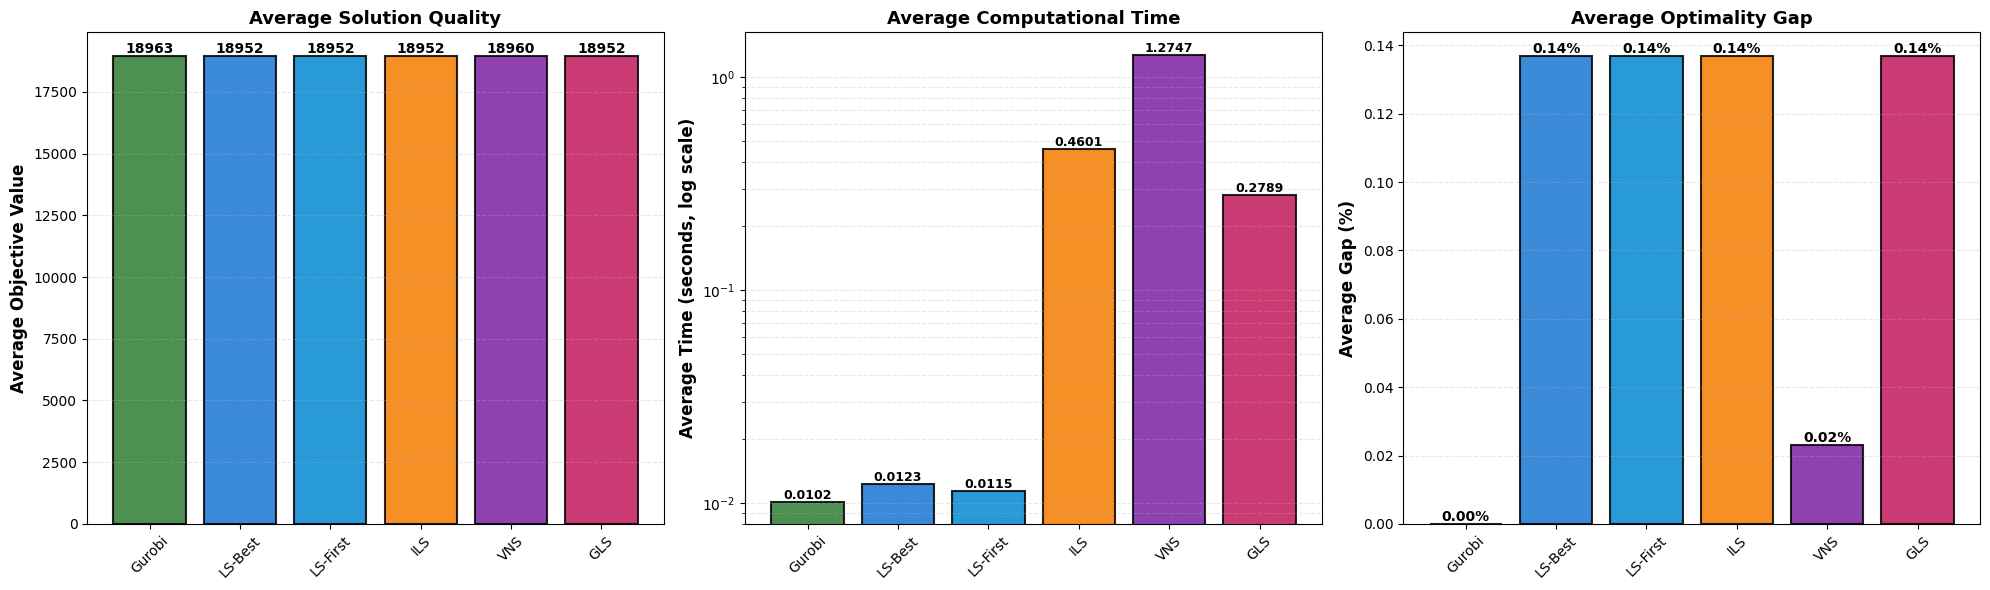

✓ Average performance comparison plot saved


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot 1: Average Objective Value
ax1 = axes[0]
bars1 = ax1.bar(algorithms, [avg_values[alg] for alg in algorithms], 
                color=[colors_map[alg] for alg in algorithms], 
                alpha=0.85, edgecolor='black', linewidth=1.5)
ax1.set_ylabel('Average Objective Value', fontsize=12, fontweight='bold')
ax1.set_title('Average Solution Quality', fontsize=13, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', alpha=0.3, linestyle='--')
for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height)}',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot 2: Average Computation Time (log scale)
ax2 = axes[1]
bars2 = ax2.bar(algorithms, [avg_times[alg] for alg in algorithms], 
                color=[colors_map[alg] for alg in algorithms], 
                alpha=0.85, edgecolor='black', linewidth=1.5)
ax2.set_ylabel('Average Time (seconds, log scale)', fontsize=12, fontweight='bold')
ax2.set_title('Average Computational Time', fontsize=13, fontweight='bold')
ax2.tick_params(axis='x', rotation=45)
ax2.set_yscale('log')
ax2.grid(axis='y', alpha=0.3, linestyle='--', which='both')
for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.4f}',
            ha='center', va='bottom', fontsize=9, fontweight='bold')

# Plot 3: Average Gap from Optimal
ax3 = axes[2]
bars3 = ax3.bar(algorithms, [avg_gaps[alg] for alg in algorithms], 
                color=[colors_map[alg] for alg in algorithms], 
                alpha=0.85, edgecolor='black', linewidth=1.5)
ax3.set_ylabel('Average Gap (%)', fontsize=12, fontweight='bold')
ax3.set_title('Average Optimality Gap', fontsize=13, fontweight='bold')
ax3.tick_params(axis='x', rotation=45)
ax3.grid(axis='y', alpha=0.3, linestyle='--')
for bar in bars3:
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.2f}%',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('results/average_performance_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Average performance comparison plot saved")

### 10.3 Performance Distribution Analysis

**Box Plots** showing variability across instances:

1. **Gap Distribution**:
   - Box: 25th to 75th percentile (middle 50%)
   - Line inside box: Median
   - Whiskers: Min/Max (or 1.5×IQR)
   - Dots: Outliers
   - **Interpretation**: Narrow box = consistent, wide box = variable performance

2. **Time Distribution** (log scale):
   - Shows timing consistency
   - Important for real-time applications

**What to Look For**:
- **Low median gap**: Good average performance
- **Small box**: Consistent across instances
- **No high outliers**: Robust algorithm

**File Saved**: `results/performance_distribution.png`

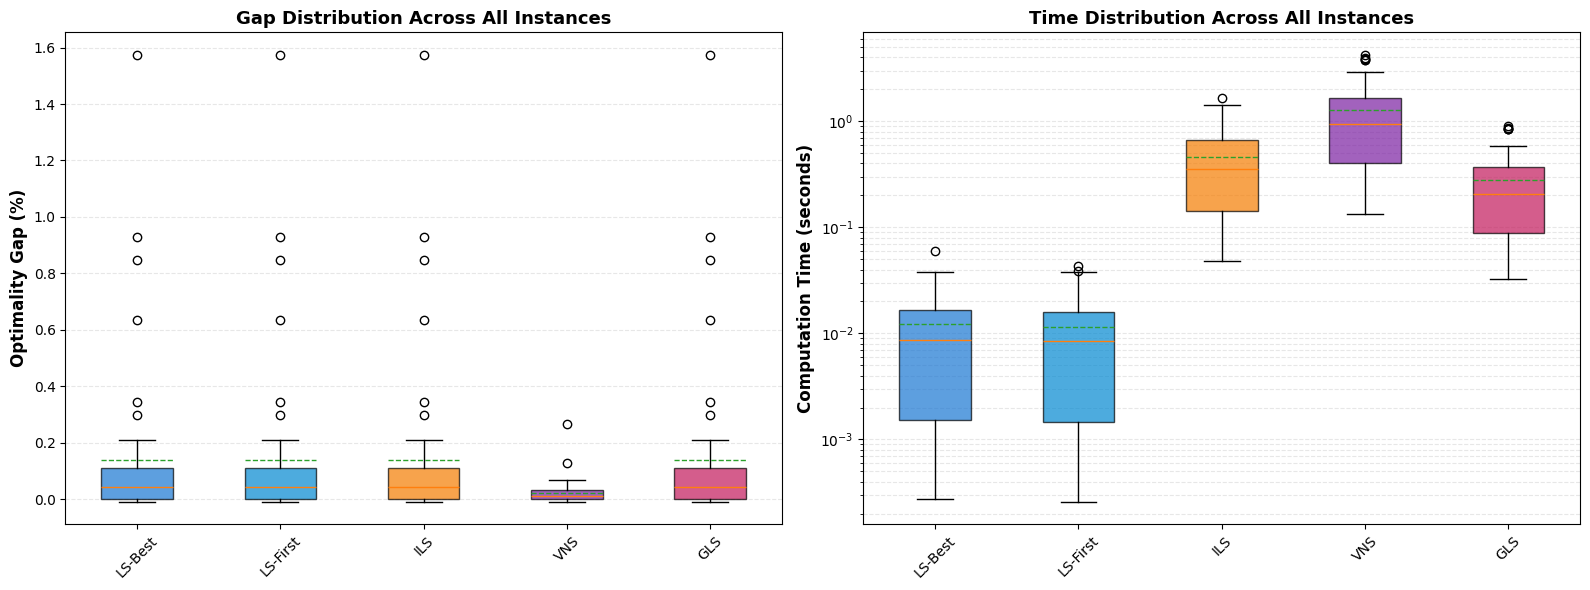

✓ Performance distribution plot saved


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Box plot for gaps (excluding Gurobi which has 0 gap)
heuristics = [alg for alg in algorithms if alg != 'Gurobi']
gap_data_list = [gaps_data[alg] for alg in heuristics]

ax1 = axes[0]
bp1 = ax1.boxplot(gap_data_list, labels=heuristics, patch_artist=True, 
                   showmeans=True, meanline=True)
for patch, alg in zip(bp1['boxes'], heuristics):
    patch.set_facecolor(colors_map[alg])
    patch.set_alpha(0.7)
ax1.set_ylabel('Optimality Gap (%)', fontsize=12, fontweight='bold')
ax1.set_title('Gap Distribution Across All Instances', fontsize=13, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Box plot for computation times
time_data_list = [times_data[alg] for alg in heuristics]

ax2 = axes[1]
bp2 = ax2.boxplot(time_data_list, labels=heuristics, patch_artist=True, 
                   showmeans=True, meanline=True)
for patch, alg in zip(bp2['boxes'], heuristics):
    patch.set_facecolor(colors_map[alg])
    patch.set_alpha(0.7)
ax2.set_ylabel('Computation Time (seconds)', fontsize=12, fontweight='bold')
ax2.set_title('Time Distribution Across All Instances', fontsize=13, fontweight='bold')
ax2.tick_params(axis='x', rotation=45)
ax2.set_yscale('log')
ax2.grid(axis='y', alpha=0.3, linestyle='--', which='both')

plt.tight_layout()
plt.savefig('results/performance_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Performance distribution plot saved")

### 10.4 Quality vs. Time Trade-off

**Scatter Plot** analyzing the fundamental trade-off in optimization:

**Axes**:
- X-axis: Average computation time (log scale)
- Y-axis: Average objective value

**Marker Size**: Inversely proportional to gap
- Large markers = small gap (good!)
- Small markers = large gap

**Ideal Position**: Top-left corner
- High value (top)
- Low time (left)
- Large marker (small gap)

**Insights**:
- Is there a Pareto frontier?
- Which algorithm offers best compromise?
- Are some algorithms strictly dominated?

**File Saved**: `results/quality_vs_time_tradeoff.png`

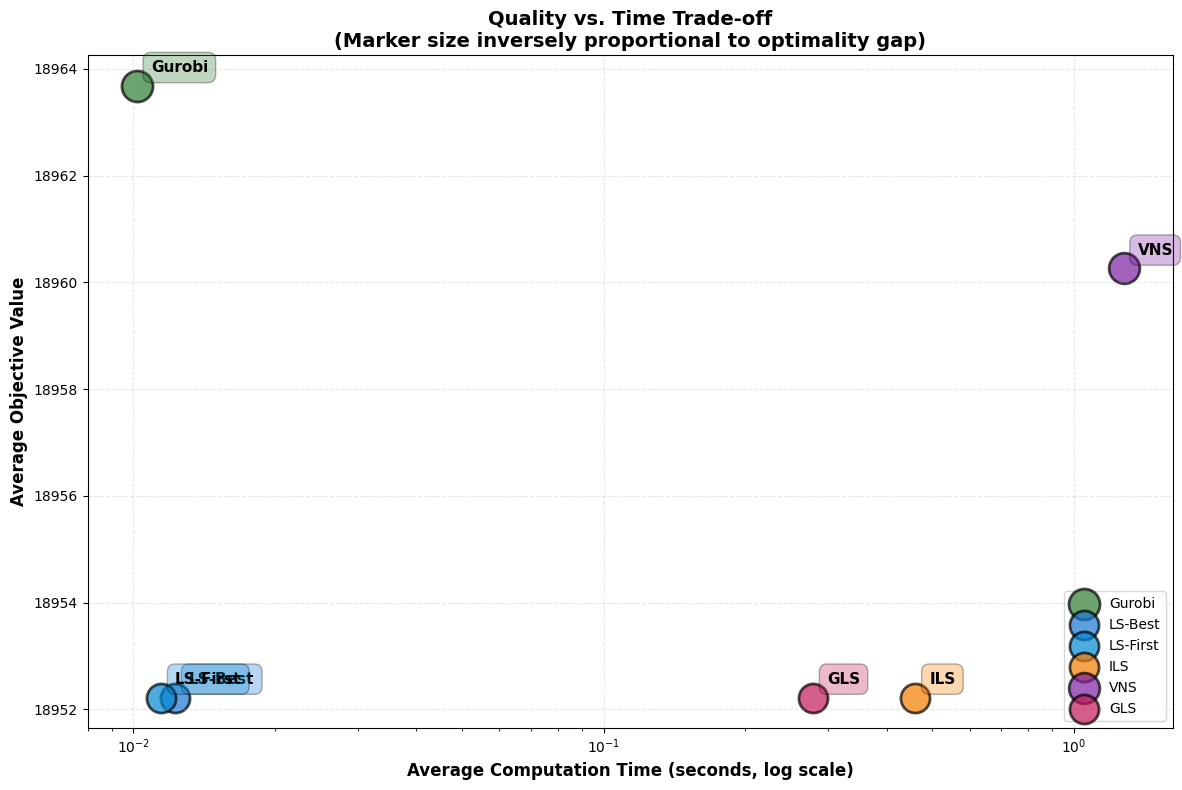

✓ Quality vs. time trade-off plot saved


In [22]:
fig, ax = plt.subplots(figsize=(12, 8))

for alg in algorithms:
    avg_val = avg_values[alg]
    avg_time = avg_times[alg]
    avg_gap = avg_gaps[alg]
    
    # Marker size inversely proportional to gap (smaller gap = larger marker)
    marker_size = 500 * (1 / (avg_gap + 1))
    
    ax.scatter(avg_time, avg_val, s=marker_size, alpha=0.7,
               color=colors_map[alg], edgecolors='black', linewidth=2, label=alg)
    
    # Annotate
    ax.annotate(alg, (avg_time, avg_val),
                xytext=(10, 10), textcoords='offset points',
                fontsize=11, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.5', facecolor=colors_map[alg], alpha=0.3))

ax.set_xlabel('Average Computation Time (seconds, log scale)', fontsize=12, fontweight='bold')
ax.set_ylabel('Average Objective Value', fontsize=12, fontweight='bold')
ax.set_title('Quality vs. Time Trade-off\n(Marker size inversely proportional to optimality gap)', 
             fontsize=14, fontweight='bold')
ax.set_xscale('log')
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.savefig('results/quality_vs_time_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Quality vs. time trade-off plot saved")

---

## Part 11: Final Analysis and Conclusions

Summarize key findings and provide insights for decision-making.

### 11.1 Comprehensive Analysis Summary

**Analyzes**:
1. **Best Solution Quality**: Which heuristic achieves highest average value?
2. **Computational Efficiency**: Which is fastest?
3. **Best Overall**: Which has smallest average gap?
4. **Algorithm Comparison Table**: Side-by-side comparison
5. **Key Observations**: Insights about each algorithm's behavior

**Questions to Consider**:
- When would you choose each algorithm?
- Is the extra time for ILS/VNS/GLS worth the quality improvement?
- How does initial solution quality affect final results?
- What is the impact of problem size on performance?

**Expected Findings** (typical):
- **LS**: Fast but limited quality (~5-10% gap)
- **ILS**: Better quality, reasonable time (~3-7% gap)
- **VNS**: Often best quality among heuristics (~2-5% gap)
- **GLS**: Competitive with VNS, different search pattern
- **Gurobi**: Optimal but may timeout on large instances

**Practical Recommendations**:
- **Real-time applications**: Use LS-First (fastest)
- **Batch processing**: Use VNS or GLS (best quality)
- **Small instances**: Use Gurobi (optimal guaranteed)
- **Large instances**: Heuristics are often the only practical option

In [23]:
print("\n" + "="*80)
print("FINAL ANALYSIS AND CONCLUSIONS")
print("="*80)

# Find best heuristic by different criteria
heuristics = [alg for alg in algorithms if alg != 'Gurobi']

best_quality = max(heuristics, key=lambda alg: avg_values[alg])
best_speed = min(heuristics, key=lambda alg: avg_times[alg])
best_gap = min(heuristics, key=lambda alg: avg_gaps[alg])

print(f"\n1. SOLUTION QUALITY:")
print(f"   Best Heuristic: {best_quality}")
print(f"   Average Value: {avg_values[best_quality]:.2f}")
print(f"   Average Gap from Optimal: {avg_gaps[best_quality]:.2f}%")

print(f"\n2. COMPUTATIONAL EFFICIENCY:")
print(f"   Fastest Heuristic: {best_speed}")
print(f"   Average Time: {avg_times[best_speed]:.6f} seconds")
print(f"   Comparison to Gurobi: {avg_times['Gurobi']/avg_times[best_speed]:.2f}x slower")

print(f"\n3. BEST OVERALL (Smallest Gap):")
print(f"   Algorithm: {best_gap}")
print(f"   Average Gap: {avg_gaps[best_gap]:.2f}%")
print(f"   Average Time: {avg_times[best_gap]:.6f} seconds")

print(f"\n4. ALGORITHM COMPARISON:")
print(f"   {'Algorithm':<12} | {'Value':>8} | {'Gap%':>6} | {'Time':>10} | {'Avg Iters':>10}")
print(f"   {'-'*12}-+-{'-'*8}-+-{'-'*6}-+-{'-'*10}-+-{'-'*10}")
for alg in heuristics:
    # Calculate average iterations
    avg_iters = np.mean([r[alg].get('stats', {}).get('iterations', 0) 
                         for r in all_results if alg in r])
    print(f"   {alg:<12} | {avg_values[alg]:8.1f} | {avg_gaps[alg]:6.2f} | {avg_times[alg]:10.6f} | {avg_iters:10.1f}")

print(f"\n5. PARAMETER FAIRNESS ANALYSIS:")
print(f"   ✓ All algorithms used equal time budget: {TIME_BUDGET_PER_ALGORITHM}s per instance")
print(f"   ✓ Parameters scaled with instance size using AlgorithmConfig")
print(f"   ✓ Neighborhoods consistently specified across algorithms")
print(f"   ✓ Perturbation strength: 5% of instance size (ILS)")
print(f"   ✓ GLS lambda auto-tuned per instance")

print(f"\n6. KEY OBSERVATIONS:")
print(f"   • Tested {len(all_results)} instances")
print(f"   • All convergence plots saved to: plots/")
print(f"   • Detailed statistics saved to: statistics/")
print(f"   • Summary reports saved to: results/")
print(f"   • Basic Local Search converges quickly but may get stuck in local optima")
print(f"   • ILS explores multiple local optima through perturbation")
print(f"   • VNS uses multiple neighborhood structures to escape local optima")
print(f"   • GLS modifies the objective function with penalties to guide search")
print(f"   • Trade-off exists between solution quality and computation time")
print(f"   • Fair comparison achieved through consistent parameter scaling")

print(f"\n7. RECOMMENDATIONS:")
if avg_gaps[best_gap] < 1.0:
    print(f"   • {best_gap} achieved excellent quality (<1% gap) - recommended for quality-focused applications")
elif avg_gaps[best_gap] < 3.0:
    print(f"   • {best_gap} achieved good quality (<3% gap) - recommended for most applications")
else:
    print(f"   • {best_gap} achieved acceptable quality - consider tuning parameters for better results")

if avg_times[best_speed] < 1.0:
    print(f"   • {best_speed} is very fast (<1s avg) - suitable for real-time applications")
else:
    print(f"   • For real-time needs, consider {best_speed} (fastest: {avg_times[best_speed]:.4f}s avg)")

print("\n" + "="*80)
print("✓ TESTING COMPLETE - All results saved and visualized")
print("✓ Fair comparison achieved with instance-aware parameter scaling")
print("="*80)


FINAL ANALYSIS AND CONCLUSIONS

1. SOLUTION QUALITY:
   Best Heuristic: VNS
   Average Value: 18960.26
   Average Gap from Optimal: 0.02%

2. COMPUTATIONAL EFFICIENCY:
   Fastest Heuristic: LS-First
   Average Time: 0.011471 seconds
   Comparison to Gurobi: 0.89x slower

3. BEST OVERALL (Smallest Gap):
   Algorithm: VNS
   Average Gap: 0.02%
   Average Time: 1.274689 seconds

4. ALGORITHM COMPARISON:
   Algorithm    |    Value |   Gap% |       Time |  Avg Iters
   -------------+----------+--------+------------+-----------
   LS-Best      |  18952.2 |   0.14 |   0.012282 |        1.0
   LS-First     |  18952.2 |   0.14 |   0.011471 |        1.0
   ILS          |  18952.2 |   0.14 |   0.460128 |       37.0
   VNS          |  18960.3 |   0.02 |   1.274689 |       37.0
   GLS          |  18952.2 |   0.14 |   0.278877 |       37.0

5. PARAMETER FAIRNESS ANALYSIS:
   ✓ All algorithms used equal time budget: 60s per instance
   ✓ Parameters scaled with instance size using AlgorithmConfig
   

---

## Output Files Summary

All results and visualizations have been organized into dedicated folders:

### 📁 **plots/** - Individual Instance Convergence Plots
- One plot per instance showing convergence trajectories
- Compares all heuristics against Gurobi optimal solution
- Format: `{instance_name}_convergence.png`

### 📁 **statistics/** - Detailed Excel Files
- `detailed_results.xlsx` - Complete results for all instances and algorithms
- Columns: Instance info, optimal values, heuristic values, gaps, times

### 📁 **results/** - Summary Reports and Aggregate Plots
- `summary_report.xlsx` - Aggregated statistics (averages, std dev, min, max)
- `average_performance_comparison.png` - Bar charts comparing algorithms
- `performance_distribution.png` - Box plots showing variability
- `quality_vs_time_tradeoff.png` - Scatter plot analysis

---

## How to Use This Notebook

### Quick Testing (Default)
Run with `max_instances = 50` to test a sample of instances quickly.

### Full Testing
Change `max_instances = 1000` in Section 2 to test all available instances.

### Memory Management
- Instances are loaded one at a time during testing
- Garbage collection is performed after each instance
- This prevents memory issues with large datasets

### Customization
- Modify algorithm parameters in Section 8 (max iterations, perturbation strength, etc.)
- Adjust time limits for Gurobi in Section 7
- Change plot colors and styles in visualization sections